### Comparison between SteadierCom and experimental results

In [1]:
import pandas as pd
import numpy as np
import json
import csv
import warnings
from os import listdir

import matplotlib.pyplot as plt
import seaborn as sns

import scipy as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,recall_score,precision_score,classification_report

import sys

sys.path.append("../functions/")

from compare_exp_sim import prepare_exp_met_venturelli,prepare_sim_met_venturelli,combine_exp_sim_met,scoring_met,plot_radar_chart

ImportError: cannot import name 'combine_exp_sim_met' from 'compare_exp_sim' (/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_exp_sim.py)

In [6]:
%load_ext autoreload
%autoreload 2

**Load 'experimental data'**

In [7]:
auxotrophies_ecoli_df = pd.read_csv("../output/Guillen2021/auxotrophies.tsv",sep="\t")

auxotrophies_ecoli_df.member = auxotrophies_ecoli_df.member.map(lambda x: "mutant_"+x)

auxotrophies_ecoli_df.compound = auxotrophies_ecoli_df.compound.map(lambda x: x.replace("R_EX_","M_"))

mutants = ['mutant_icd', 'mutant_panZ', 'mutant_bioF',
           'mutant_bioH', 'mutant_cysW', 'mutant_bioC', 'mutant_panD']
auxotrophies_ecoli_df = auxotrophies_ecoli_df.loc[auxotrophies_ecoli_df.member.isin(mutants)]
auxotrophies_ecoli_df = auxotrophies_ecoli_df[auxotrophies_ecoli_df.compound!="M_o2_e"]

signal_exp = auxotrophies_ecoli_df.set_index(["member","compound"])['0']
signal_exp  = signal_exp.unstack().fillna(0).stack()
signal_exp.name="experimental"

**Load steadiercom results**

In [8]:
steadiercom_growth = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth/ecoli_mutants.tsv",sep="\t")
steadiercom_abundance = pd.read_csv("../output/Guillen2021/results_steadiercom/results_abundance/ecoli_mutants.tsv",sep="\t")
steadiercom_growth_abundance = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth_abundance/ecoli_mutants.tsv",sep="\t")


**Load smetana results**

In [9]:
smetana = pd.read_csv("../output/Guillen2021/smetana/_detailed.tsv",sep="\t")


**Load steadycom results**

In [10]:
steadycom_fixed_abundance = pd.read_csv("../output/Guillen2021/steadycom/fixed_abundance/cross_feeding.tsv",sep="\t")
steadycom = pd.read_csv("../output/Guillen2021/steadycom/no_abundance/cross_feeding.tsv",sep="\t")

**Process data - add met_group to columns**

In [11]:

steadiercom_dict = {
    "SteadierCom - fixed growth":steadiercom_growth,
    "SteadierCom - fixed growth & abundance":steadiercom_growth_abundance,
    "SteadierCom - fixed abundance":steadiercom_abundance
}

steadycom_dict = {
    "SteadyCom - Nothing fixed":steadycom,
    "SteadyCom - Fixed  abundance":steadycom_fixed_abundance
}

smetana_dict = {"Smetana":smetana}



simulation_dict = {"receiver" : {"steadiercom": {key: value[value["receiver"]!="environment"].copy()
                                          for key, value in steadiercom_dict.items()},
                               "steadycom":{key: value[~value["receiver"].isna()].copy()
                                          for key, value in steadycom_dict.items()},
                                "smetana":{key: value
                                          for key, value in smetana_dict.items()}
                                  },
                     "donor": {"steadiercom": {key: value[value["donor"]!="environment"].copy()
                                          for key, value in steadiercom_dict.items()},
                               "steadycom":{key: value[~value["donor"].isna()].copy()
                                          for key, value in steadycom_dict.items()},
                                "smetana":{key: value
                                          for key, value in smetana_dict.items()}
                                  },
                    }

#### Receivers - SteadierCom - scatterplot - frequency

NameError: name 'combine_exp_sim_met' is not defined

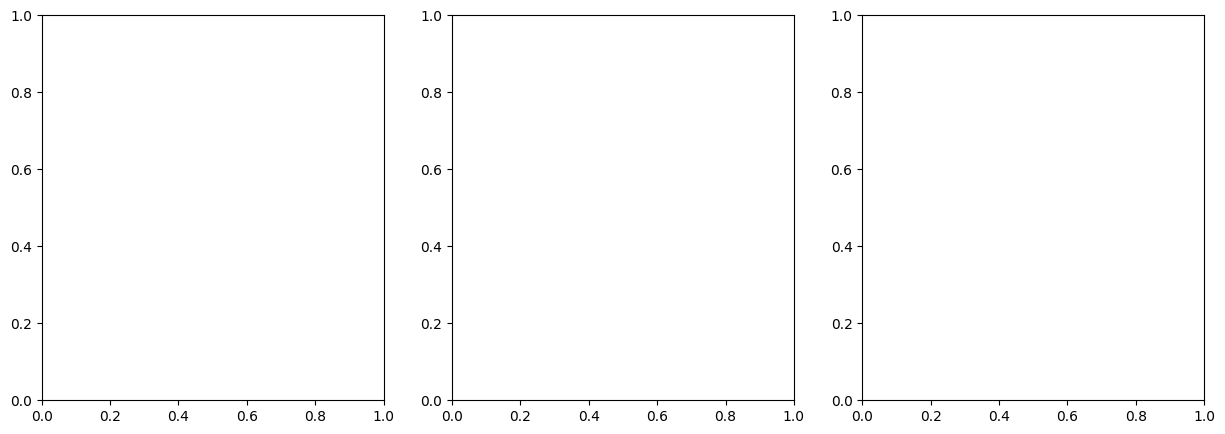

In [12]:
receiver_or_donor="receiver"

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name, simulated_res in simulation_dict[receiver_or_donor]["steadiercom"].items():
    
    ## Process simulated result
    exp_sim_combined = combine_exp_sim_met(simulated_res,
                                       signal_exp,
                                       metric="frequency",
                                       agg_method="sum",
                                       receiver_or_donor=receiver_or_donor,
                                       met_column="compound")
    
    exp_sim_combined = exp_sim_combined.dropna()
    
    sns.scatterplot(ax=axs[i], x="experimental", y="simulated", data=exp_sim_combined)
    axs[i].set_title(name)
    
    r, p = sp.stats.spearmanr(exp_sim_combined)
    plt.text(.1, .85, "Spearman's r={:.2f}, p-value={:.4f}".format(r,p), transform=axs[i].transAxes)

    
    i+=1

In [13]:
permutation_test = sp.stats.permutation_test((exp_sim_combined.simulated,exp_sim_combined.experimental),
                          statistic = lambda x, y: sp.stats.spearmanr(x, y).statistic,
                          permutation_type="independent",
                          n_resamples=10_000,
                          alternative="two-sided")

permutation_test

NameError: name 'exp_sim_combined' is not defined

#### Receivers - SteadierCom - scatterplot - rate

NameError: name 'combine_exp_sim_met' is not defined

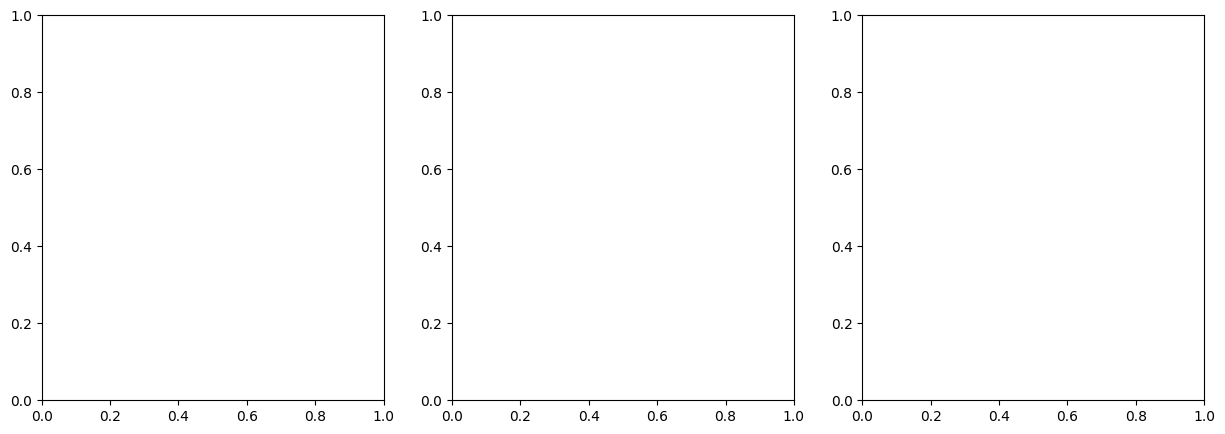

In [14]:
receiver_or_donor="receiver"

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name, simulated_res in simulation_dict[receiver_or_donor]["steadiercom"].items():
    
    ## Process simulated result
    exp_sim_combined = combine_exp_sim_met(simulated_res,
                                       signal_exp,
                                       metric="rate",
                                       agg_method="sum", #sum
                                       receiver_or_donor=receiver_or_donor,
                                       met_column="compound")
    exp_sim_combined = exp_sim_combined.dropna()
    
    sns.scatterplot(ax=axs[i], x="experimental", y="simulated", data=exp_sim_combined)
    axs[i].set_title(name)
    
    r, p = sp.stats.spearmanr(exp_sim_combined)
    plt.text(.1, .85, "Spearman's r={:.2f}, p-value={:.4f}".format(r,p), transform=axs[i].transAxes)

    
    i+=1

In [15]:
permutation_test = sp.stats.permutation_test((exp_sim_combined.simulated,exp_sim_combined.experimental),
                          statistic = lambda x, y: sp.stats.spearmanr(x, y).statistic,
                          permutation_type="independent",
                          n_resamples=10_000,
                          alternative="two-sided")

permutation_test

NameError: name 'exp_sim_combined' is not defined

#### Receivers - SteadyCom - scatterplot

NameError: name 'combine_exp_sim_met' is not defined

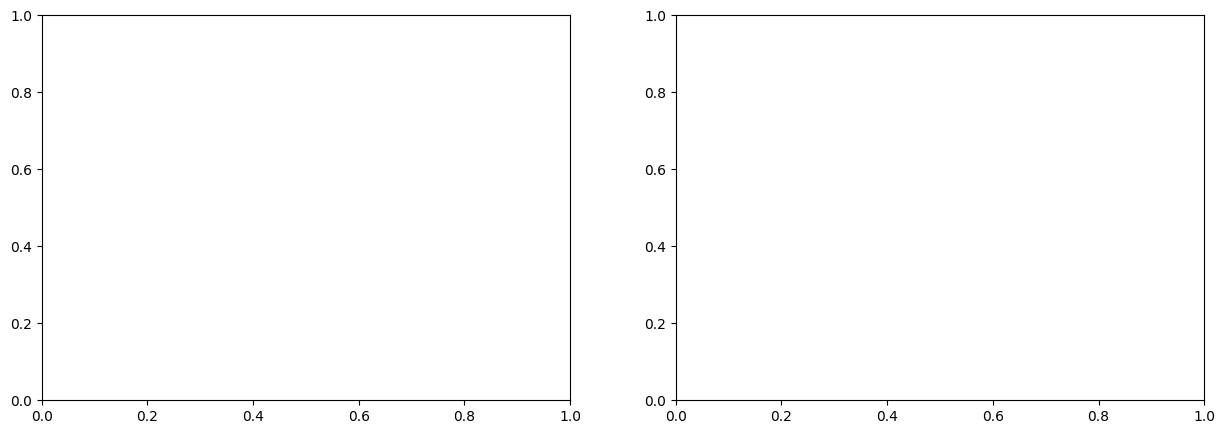

In [16]:
receiver_or_donor="receiver"

fig, axs = plt.subplots(1,2,figsize=(15,5))

i = 0
for name, simulated_res in simulation_dict[receiver_or_donor]["steadycom"].items():
    
    ## Process simulated result
    exp_sim_combined = combine_exp_sim_met(simulated_res,
                                           signal_exp,
                                           metric="rate?",                                       
                                           agg_method="sum", #sum
                                           receiver_or_donor=receiver_or_donor,
                                           met_column="compound")
    exp_sim_combined = exp_sim_combined.dropna()
    sns.scatterplot(ax=axs[i], x="experimental", y="simulated", data=exp_sim_combined)
    axs[i].set_title(name)
    
    r, p = sp.stats.spearmanr(exp_sim_combined)
    plt.text(.1, .85, "Spearman's r={:.2f}, p-value={:.4f}".format(r,p), transform=axs[i].transAxes)
    
    i+=1

#### Receivers - SMETANA - scatterplot

NameError: name 'combine_exp_sim_met' is not defined

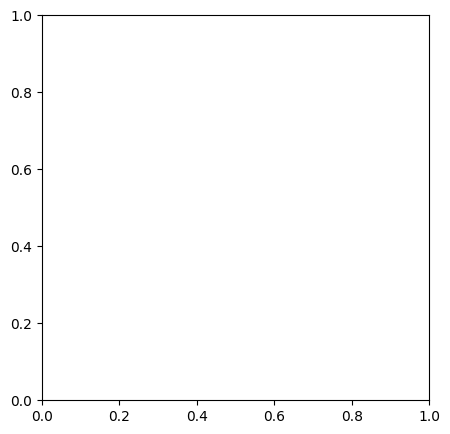

In [17]:
receiver_or_donor="receiver"

fig, axs = plt.subplots(1,1,figsize=(5,5))

i = 0
for name, simulated_res in simulation_dict[receiver_or_donor]["smetana"].items():
    
    ## Process simulated result
    exp_sim_combined = combine_exp_sim_met(simulated_res,
                                           signal_exp,
                                           metric="mus",                                       
                                           agg_method="mean", #sum
                                           receiver_or_donor=receiver_or_donor,
                                           met_column="compound")
    exp_sim_combined = exp_sim_combined.dropna()
    sns.scatterplot(ax=axs, x="experimental", y="simulated", data=exp_sim_combined)
    axs.set_title(name)
    
    r, p = sp.stats.spearmanr(exp_sim_combined)
    plt.text(.1, .85, "Spearman's r={:.2f}, p-value={:.4f}".format(r,p), transform=axs.transAxes)
    
    i+=1

## Confusion matrices

#### Receiver - SteadierCom and SteadyCom - rate

In [18]:
def plot_confusion_matrix_guillen(simulation_dict,signal_exp,receiver_or_donor="receiver",steadycom_or_smetana="steadycom"):
    if steadycom_or_smetana=="steadycom":
        cf_sim_data_dict = {**{key:(value,"rate") for key,value in simulation_dict[receiver_or_donor]["steadiercom"].items()},
                            **{key:(value,"rate?") for key,value in simulation_dict[receiver_or_donor]["steadycom"].items()}} 
        fig,axs=plt.subplots(2,3,figsize=(15,10))
        axs_flat = axs.flatten()

    elif steadycom_or_smetana=="smetana":
        cf_sim_data_dict = {**{key:(value,"frequency") for key,value in simulation_dict[receiver_or_donor]["steadiercom"].items()},
                            **{key:(value,"mus") for key,value in simulation_dict[receiver_or_donor]["smetana"].items()}} 
    
        fig,axs=plt.subplots(2,2,figsize=(10,10))
        axs_flat = axs.flatten()
    else:
        raise Exception("Choose either steadycom or smetana for 'steadycom_or_smetana'")
    
    sim_thresh_rate = 1e-5
    sim_thresh_freq = 0.1

    # start plot
    i = 0

    for name,(sim_df,metric) in cf_sim_data_dict.items():
        exp_sim_combined = combine_exp_sim_met(sim_df,
                                       signal_exp,
                                       agg_method="sum", #sum
                                       metric=metric,   
                                       receiver_or_donor=receiver_or_donor,
                                       met_column="compound")
        
        if receiver_or_donor=="receiver":
            exp_sim_combined.experimental = exp_sim_combined.experimental>0.5
        else:
            raise Exception("Only receivers are supported for the Guillen study")
        
            
        if steadycom_or_smetana=="steadycom":
            exp_sim_combined.simulated = exp_sim_combined.simulated>sim_thresh_rate            
        elif steadycom_or_smetana=="smetana":
            exp_sim_combined.simulated = exp_sim_combined.simulated>sim_thresh_freq
        
        cf_matrix = confusion_matrix(exp_sim_combined.experimental, exp_sim_combined.simulated)


        ax = sns.heatmap(cf_matrix, 
                         annot = cf_matrix,
                         fmt="", cmap='winter_r',vmin=0,vmax=24, ax=axs_flat[i])
        ax.set_ylabel("Experimental")
        ax.set_xlabel("Simulated")
        ax.set_yticklabels(["False","True"])
        ax.set_xticklabels(["False","True"])
        ax.set_title(name)
        i +=1
    fig.suptitle(receiver_or_donor)
    return fig,axs_flat

#### Receiver - SteadierCom and SteadyCom - rate

NameError: name 'combine_exp_sim_met' is not defined

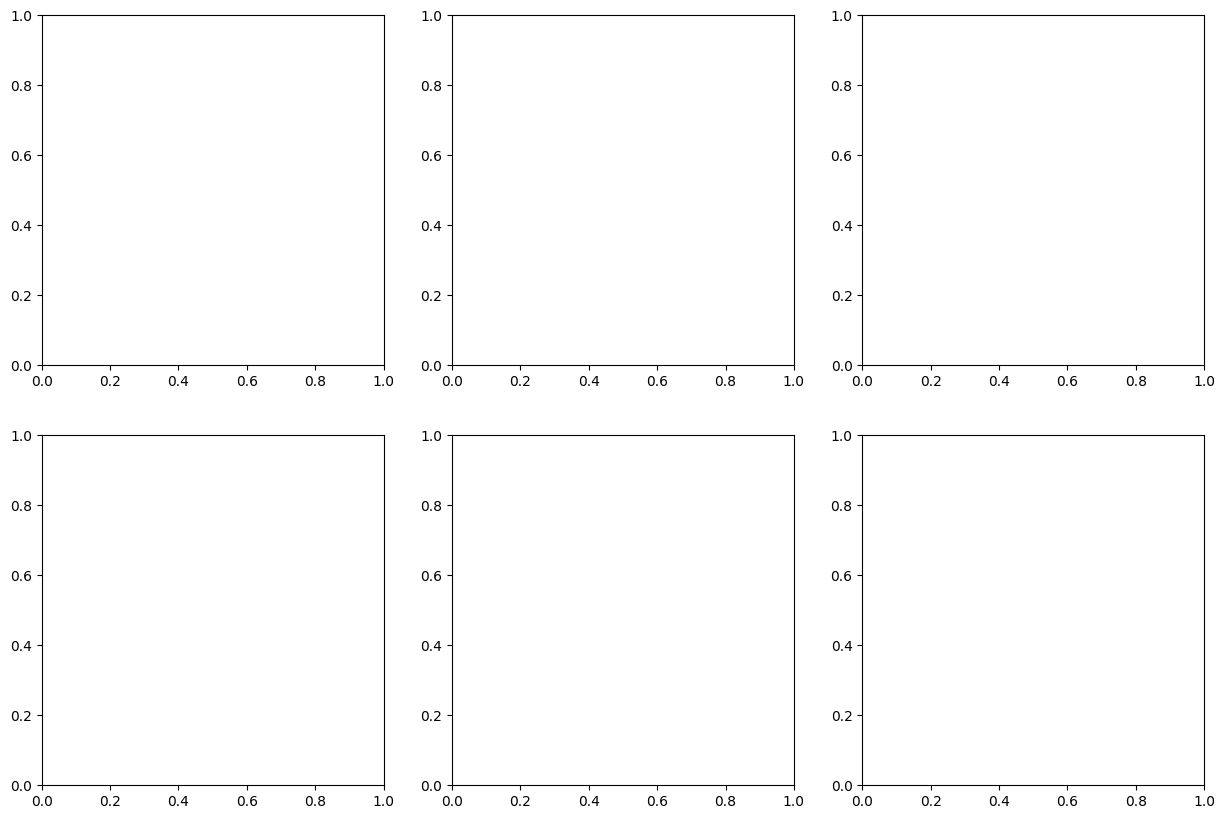

In [19]:
fig,ax = plot_confusion_matrix_guillen(simulation_dict=simulation_dict,
                                          signal_exp=signal_exp,
                                          receiver_or_donor="receiver",
                                          steadycom_or_smetana="steadycom")

#### Receiver - SteadierCom and SMETANA - frequency/MUS

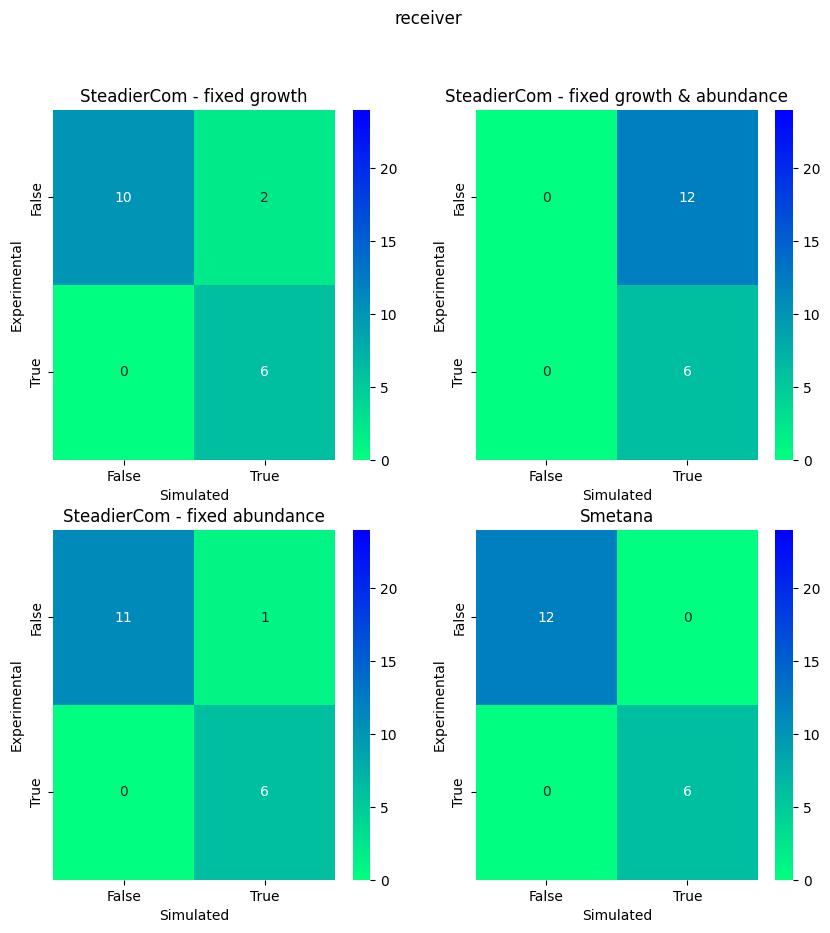

In [16]:
fig,ax = plot_confusion_matrix_guillen(simulation_dict=simulation_dict,
                                          signal_exp=signal_exp,
                                          receiver_or_donor="receiver",
                                          steadycom_or_smetana="smetana")

## Radar charts

In [17]:
simulation_dict["receiver"]["steadiercom"]["SteadierCom - fixed abundance"].rate.median()

np.float64(0.0016725323893313)

In [18]:
simulation_dict["receiver"]["steadycom"]["SteadyCom - Fixed  abundance"]["rate?"].median()

np.float64(0.588218966186556)

In [19]:
simulation_dict["receiver"]["steadiercom"]["SteadierCom - fixed abundance"].rate.max()

np.float64(2.9979783910080173)

In [20]:
simulation_dict["receiver"]["steadycom"]["SteadyCom - Fixed  abundance"]["rate?"].max()

np.float64(199.63404103366005)

In [21]:
### Receivers -  SteadierCom - Radar chart - frequency

receiver_or_donor_list = ["receiver"]

scores_dict = {}

for receiver_or_donor in receiver_or_donor_list:

    exp_condition_str = "> 0.5"

    scores_dict[receiver_or_donor]={}

    scores_dict[receiver_or_donor]["steadiercom_frequency"]= scoring_met(simulation_res_dict=simulation_dict[receiver_or_donor]["steadiercom"],
                                                       signal_exp=signal_exp,
                                                       exp_condition_str=exp_condition_str,
                                                       sim_thresh=0.1, 
                                                       agg_method="sum", 
                                                       receiver_or_donor=receiver_or_donor,
                                                       met_column="compound")


    scores_dict[receiver_or_donor]["steadiercom_rate"]=scoring_met(simulation_res_dict = simulation_dict[receiver_or_donor]["steadiercom"],
                                                        signal_exp=signal_exp,
                                                        sim_metric="rate",
                                                        exp_condition_str=exp_condition_str,
                                                        sim_thresh=1e-5,
                                                        agg_method="sum", 
                                                        receiver_or_donor=receiver_or_donor,                                       
                                                        met_column="compound")                        


    scores_dict[receiver_or_donor]["steadycom_rate"]= scoring_met(simulation_res_dict = simulation_dict[receiver_or_donor]["steadycom"],
                                                        signal_exp=signal_exp,
                                                        sim_metric="rate?",
                                                        exp_condition_str=exp_condition_str,
                                                        sim_thresh=1e-5,
                                                        agg_method="sum", 
                                                        receiver_or_donor=receiver_or_donor,
                                                        met_column="compound")
    scores_dict[receiver_or_donor]["smetana"]= scoring_met(simulation_res_dict = simulation_dict[receiver_or_donor]["smetana"],
                                                        signal_exp=signal_exp,
                                                        sim_metric="mus",
                                                        exp_condition_str=exp_condition_str,
                                                        sim_thresh=0.1,
                                                        agg_method="sum", 
                                                        receiver_or_donor=receiver_or_donor,
                                                        met_column="compound")

/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beh

### Receivers - SteadyCom vs SteadierCom - rate

Text(0.5, 0.98, 'receiver')

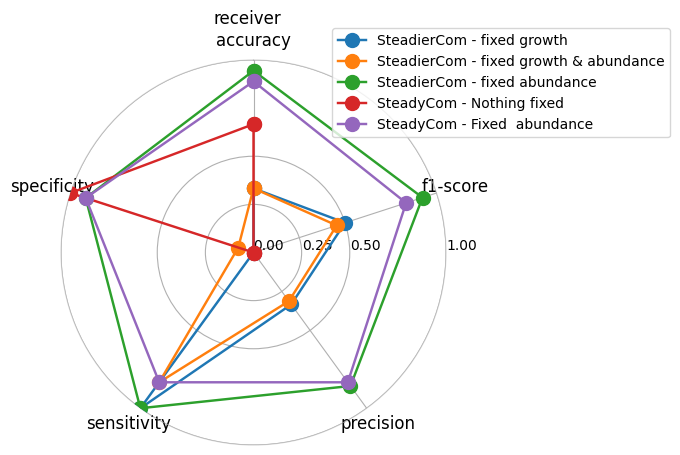

In [22]:
scores_df_all = pd.concat([scores_dict["receiver"]["steadiercom_rate"],
                           scores_dict["receiver"]["steadycom_rate"]],axis=1)

fig, ax = plot_radar_chart(scores_df_all)
fig.suptitle(receiver_or_donor)

### Receivers - SteadierCom - frequency

Text(0.5, 0.98, 'receiver')

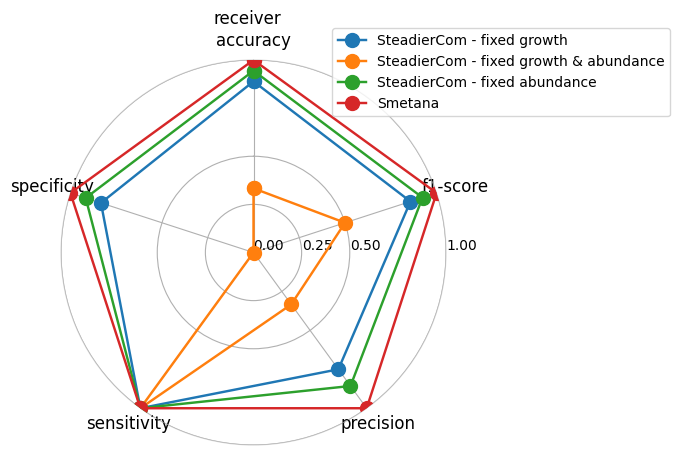

In [23]:
scores_df_all = pd.concat([scores_dict["receiver"]["steadiercom_frequency"],
                          scores_dict["receiver"]["smetana"]],axis=1)

fig, ax = plot_radar_chart(scores_df_all)
fig.suptitle(receiver_or_donor)